In [2]:
words = open('names.txt', 'r').read().splitlines()

In [3]:
import torch

In [4]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi ['.'] = 0

itos = {i:s for s, i in stoi.items()}

Exercises:
- E01: train a trigram language model, i.e. take two characters as an input to predict the 3rd one. Feel free to use either counting or a neural net. Evaluate the loss; Did it improve over a bigram model?
- E02: split up the dataset randomly into 80% train set, 10% dev set, 10% test set. Train the bigram and trigram models only on the training set. Evaluate them on dev and test splits. What can you see?
- E03: use the dev set to tune the strength of smoothing (or regularization) for the trigram model - i.e. try many possibilities and see which one works best based on the dev set loss. What patterns can you see in the train and dev set loss as you tune this strength? Take the best setting of the smoothing and evaluate on the test set once and at the end. How good of a loss do you achieve?
- E04: we saw that our 1-hot vectors merely select a row of W, so producing these vectors explicitly feels wasteful. Can you delete our use of F.one_hot in favor of simply indexing into rows of W?
- E05: look up and use F.cross_entropy instead. You should achieve the same result. Can you think of why we'd prefer to use F.cross_entropy instead?
- E06: meta-exercise! Think of a fun/interesting exercise and complete it.

## E01

note: Loss in bigram model was 2.5

In [5]:
# Trigram language model with counting
N = torch.zeros((27, 27, 27), dtype=torch.int32)

for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2, ch3 in zip(chs, chs[1:], chs[2:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    ix3 = stoi[ch3]
    N[ix1, ix2, ix3] += 1

In [6]:
P = (N+1).float()
P /= P.sum(dim=2, keepdim=True)

In [7]:
g = torch.Generator().manual_seed(2147483647)

for i in range(20):
  out = []
  ix1 = 0
  ix2 = 0
  while True:
    p = P[ix1,ix2]
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    ix1 = ix2
    ix2 = ix
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

ce.
za.
zogh.
uriana.
kaydnevonimittain.
luwak.
ka.
da.
samiyah.
javer.
gotai.
is.
iselivojkwuthda.
kaley.
maside.
en.
bvgyn.
wynnstihiliven.
tahlasuzusfxx.
leenlen.


In [8]:
log_likelihood = 0.0
n = 0
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2, ch3 in zip(chs, chs[1:], chs[2:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    ix3 = stoi[ch3]
    prob = P[ix1, ix2, ix3]
    logprob = torch.log(prob)
    log_likelihood += logprob
    n+=1
    # print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(f'{log_likelihood=}')
nll = -log_likelihood
print(f'{nll=}')
print(f'{nll/n=}')

log_likelihood=tensor(-410414.9688)
nll=tensor(410414.9688)
nll/n=tensor(2.0927)


### Functions for Birgram model


In [9]:
import torch.nn.functional as F
g = torch.Generator().manual_seed(2147483647)

def train_bigram_model_weights(xs, ys, iterations, learning_rate, W = torch.randn((27, 27), requires_grad=True, generator=g)):
  num = xs.nelement()
  print('number of examples: ', num)

  #Training loop with gradient descent

  for k in range(iterations):
    #Forward pass
    xenc = F.one_hot(xs, num_classes=27).float()
    logits = xenc @ W
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdims=True)
    loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W**2).mean()

    print(loss.item())

    #Backward pass
    W.grad = None
    loss.backward()

    #Update weights
    W.data += -learning_rate * W.grad

  return W

In [10]:
def generate_from_bigram_model(W, num_words):
  for i in range(num_words):
    out = []
    ix = 0
    while True:
      xenc = F.one_hot(ix, num_classes=27).float()
      logits = xenc @ W
      counts = logits.exp()
      p = counts / counts.sum()
      ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
      out.append(itos[ix])
      if ix == 0:
        break
    print(''.join(out))



In [20]:
def calculate_loss_for_bigram(W, xs, ys):
  num = xs.nelement()
  xenc = F.one_hot(xs, num_classes=27).float()
  logits = xenc @ W
  counts = logits.exp()
  probs = counts / counts.sum(1, keepdims=True)
  loss = -probs[torch.arange(num), ys].log().mean()

  return loss

In [42]:
def get_data_bigram(words):
  xs, ys = [], []

  for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
      ix1 = stoi[ch1]
      ix2 = stoi[ch2]
      xs.append(ix1)
      ys.append(ix2)
  xs = torch.tensor(xs)
  ys = torch.tensor(ys)

  return xs, ys

In [24]:
xs, ys = get_data_bigram(words)

In [27]:
W = torch.randn((27, 27), requires_grad=True, generator=g)


In [29]:
W = train_bigram_model_weights(xs, ys, 200, 10, W)

number of examples:  228146
2.4829440116882324
2.482938766479492
2.482933759689331
2.4829282760620117
2.4829232692718506
2.4829182624816895
2.4829134941101074
2.482908010482788
2.482902765274048
2.4828972816467285
2.4828927516937256
2.4828872680664062
2.482882261276245
2.482877254486084
2.482872247695923
2.4828670024871826
2.4828619956970215
2.4828572273254395
2.482851982116699
2.482846975326538
2.482841968536377
2.482837200164795
2.4828319549560547
2.4828271865844727
2.4828224182128906
2.4828174114227295
2.4828128814697266
2.4828076362609863
2.482802629470825
2.482797861099243
2.482793092727661
2.482788324356079
2.482783794403076
2.482778310775757
2.482773780822754
2.482769250869751
2.48276424407959
2.482759714126587
2.482755184173584
2.482750177383423
2.482745409011841
2.482740640640259
2.482736110687256
2.482731580734253
2.482726573944092
2.482722043991089
2.482717275619507
2.482713222503662
2.48270845413208
2.482703685760498
2.482699394226074
2.482694149017334
2.4826900959014893
2.

In [30]:
loss = calculate_loss_for_bigram(W, xs, ys)
print(loss.item())

2.4637765884399414


### Functions for Trigram model

In [34]:
# Trigram model with training tensors

g = torch.Generator().manual_seed(2147483647)

def train_trigram_model_weights(xs, ys, iterations, learning_rate, W = torch.randn((27, 27, 27), requires_grad=True, generator=g)):
  num = xs.nelement() // 2 # Number of trigram examples
  print('number of examples: ', num)

  #Training loop with gradient descent

  for k in range(iterations):
    #Forward pass
    logits = W[xs[:, 0], xs[:, 1]]
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdims=True)
    loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W**2).mean()
    print(loss.item())

    #Backward pass
    W.grad = None
    loss.backward()

    #Update weights
    W.data += -learning_rate * W.grad

  return W




In [35]:
def generate_from_trigram_model(W, num_words):
  for i in range(num_words):
    out = []
    ix1 = 0
    ix2 = 0
    while True:
      logits = W[ix1,ix2]
      counts = logits.exp()
      p = counts / counts.sum()
      ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
      ix1 = ix2
      ix2 = ix
      out.append(itos[ix])
      if ix == 0:
        break
    print(''.join(out))

In [36]:
def calculate_loss_for_trigram(W, xs, ys):
  num = xs.nelement() // 2
  logits = W[xs[:, 0], xs[:, 1], :]
  counts = logits.exp()
  probs = counts / counts.sum(1, keepdims=True)
  loss = -probs[torch.arange(num), ys].log().mean()

  return loss

In [37]:
def get_data_trigram(words):
  xs, ys = [], []

  for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2, ch3 in zip(chs, chs[1:], chs[2:]):
      ix1 = stoi[ch1]
      ix2 = stoi[ch2]
      ix3 = stoi[ch3]
      xs.append((ix1, ix2))
      ys.append(ix3)
  xs = torch.tensor(xs)
  ys = torch.tensor(ys)

  return xs, ys

### Training trigram model

In [38]:
xs, ys = get_data_trigram(words)

In [39]:
W = torch.randn((27, 27, 27), requires_grad=True, generator=g)

In [44]:
W = train_trigram_model_weights(xs, ys, 200, 10, W)

number of examples:  196113
2.2699508666992188
2.2697999477386475
2.2696492671966553
2.2694990634918213
2.2693490982055664
2.2691996097564697
2.269049644470215
2.2689006328582764
2.268751621246338
2.2686026096343994
2.268454074859619
2.268305778503418
2.268157482147217
2.268009901046753
2.26786208152771
2.267714500427246
2.2675676345825195
2.267420768737793
2.2672743797302246
2.2671279907226562
2.266981840133667
2.2668356895446777
2.266690492630005
2.266545057296753
2.266399621963501
2.2662546634674072
2.2661099433898926
2.265965461730957
2.2658212184906006
2.2656772136688232
2.265533447265625
2.265389919281006
2.265246868133545
2.265103578567505
2.264960765838623
2.264817953109741
2.2646756172180176
2.264533758163452
2.2643914222717285
2.264249801635742
2.264108180999756
2.263967514038086
2.2638258934020996
2.263685464859009
2.263544797897339
2.263404369354248
2.2632644176483154
2.263124465942383
2.2629847526550293
2.262845516204834
2.2627062797546387
2.2625670433044434
2.262428522109

In [43]:
loss = calculate_loss_for_trigram(W, xs, ys)
print(loss.item())

2.259653091430664


In [46]:
generate_from_trigram_model(W, 20)

olucus.
xxon.
assid.
wicvpgjton.
yzykeniah.
padqszajaqxqeknpyfjcuwa.
mvxuiszyrivarqzdbson.
har.
colaylies.
el.
patfqqouhal.
rie.
alkgoluckie.
marayaavan.
noelluhanan.
xbane.
wypjdjkxdtza.
.
wil.
emaideranio.


Trigram loss  = 2.15 < 2.5 (bigram model)

## E02: split up the dataset randomly into 80% train set, 10% dev set, 10% test set. Train the bigram and trigram models only on the training set. Evaluate them on dev and test splits. What can you see?

In [47]:
from torch.utils.data import TensorDataset

In [49]:
def get_test_train_dev_data(xs, ys, g = torch.Generator().manual_seed(2147483647)):
  '''
  Splits the data into train, dev and test sets with ratio 80:10:10
  '''

  dataset = TensorDataset(xs, ys)

  train_size = int(0.8 * len(dataset))
  dev_size = int(0.1 * len(dataset))
  test_size = len(dataset) - train_size - dev_size

  train_dataset, dev_dataset, test_dataset = torch.utils.data.random_split(dataset, [train_size, dev_size, test_size], generator=g)

  print(f'Train size: {len(train_dataset)}')
  print(f'Dev size: {len(dev_dataset)}')
  print(f'Test size: {len(test_dataset)}')

  return train_dataset, dev_dataset, test_dataset




bigram model training and testing with splits

In [119]:
xs, ys = get_data_bigram(words)

In [120]:
train, dev, test= get_test_train_dev_data(xs, ys)

Train size: 182516
Dev size: 22814
Test size: 22816


In [121]:
W_bigram = torch.rand((27,27), requires_grad=True, generator=g)

In [122]:
x_train = torch.stack([data[0] for data in train])
y_train = torch.stack([data[1] for data in train])

x_dev = torch.stack([data[0] for data in dev])
y_dev = torch.stack([data[1] for data in dev])

x_test = torch.stack([data[0] for data in test])
y_test = torch.stack([data[1] for data in test])

In [127]:
W_bigram = train_bigram_model_weights(x_train, y_train, 100, 1, W_bigram)

number of examples:  182516
2.48224139213562
2.48224139213562
2.482240915298462
2.482240676879883
2.4822404384613037
2.4822402000427246
2.4822399616241455
2.4822397232055664
2.482239246368408
2.482239007949829
2.48223876953125
2.482238531112671
2.482238531112671
2.4822380542755127
2.4822378158569336
2.4822373390197754
2.4822373390197754
2.482236862182617
2.482236862182617
2.482236623764038
2.48223614692688
2.4822356700897217
2.4822354316711426
2.4822351932525635
2.4822349548339844
2.4822347164154053
2.482234239578247
2.482234001159668
2.482233762741089
2.4822335243225098
2.4822335243225098
2.4822330474853516
2.4822328090667725
2.4822323322296143
2.482232093811035
2.482231855392456
2.482231378555298
2.4822311401367188
2.482231378555298
2.4822306632995605
2.4822306632995605
2.4822304248809814
2.4822299480438232
2.482229709625244
2.482229709625244
2.482229232788086
2.482228994369507
2.4822287559509277
2.4822282791137695
2.4822280406951904
2.4822280406951904
2.4822275638580322
2.4822273254

In [128]:
bigram_dev_loss = calculate_loss_for_bigram(W_bigram, x_dev, y_dev)
print(bigram_dev_loss.item())

2.46766996383667


In [129]:
bigram_test_loss = calculate_loss_for_bigram(W_bigram, x_test, y_test)
print(bigram_test_loss.item())

2.4647743701934814


Trigram model with test train splits

In [89]:
xs, ys = get_data_trigram(words)

In [90]:
train, dev, test = get_test_train_dev_data(xs, ys)

Train size: 156890
Dev size: 19611
Test size: 19612


In [91]:
x_train = torch.stack([data[0] for data in train])
y_train = torch.stack([data[1] for data in train])

x_dev = torch.stack([data[0] for data in dev])
y_dev = torch.stack([data[1] for data in dev])

x_test = torch.stack([data[0] for data in test])
y_test = torch.stack([data[1] for data in test])

In [93]:
W = torch.rand((27,27,27), requires_grad=True, generator=g)

In [108]:
W = train_trigram_model_weights(x_train, y_train, 100, 10, W)

number of examples:  156890
2.1127665042877197
2.1127612590789795
2.1127560138702393
2.11275053024292
2.1127452850341797
2.1127400398254395
2.1127350330352783
2.112729549407959
2.1127243041992188
2.1127190589904785
2.1127138137817383
2.112708568572998
2.112703561782837
2.1126978397369385
2.1126928329467773
2.112687826156616
2.112682342529297
2.1126770973205566
2.1126718521118164
2.112666606903076
2.112661361694336
2.1126561164855957
2.1126511096954346
2.1126458644866943
2.112640380859375
2.112635612487793
2.1126303672790527
2.1126246452331543
2.112619638442993
2.112614393234253
2.1126091480255127
2.1126041412353516
2.1125986576080322
2.112593650817871
2.1125881671905518
2.1125829219818115
2.1125781536102295
2.11257266998291
2.112567663192749
2.112562417984009
2.1125569343566895
2.1125519275665283
2.112546682357788
2.112541437149048
2.1125364303588867
2.1125311851501465
2.1125259399414062
2.112520694732666
2.112515449523926
2.1125106811523438
2.1125051975250244
2.112499952316284
2.11249

In [110]:
trigram_dev_loss = calculate_loss_for_trigram(W, x_dev, y_dev)
print(trigram_dev_loss.item())

2.115175724029541


In [111]:
trigram_test_loss = calculate_loss_for_trigram(W, x_test, y_test)
print(trigram_test_loss.item())

2.13533616065979


In [131]:
import pandas as pd

data = {'Model': ['Bigram', 'Trigram'],
        'Dev Loss': [bigram_dev_loss.item(), trigram_dev_loss.item()],
        'Test Loss': [bigram_test_loss.item(), trigram_test_loss.item()]}
df = pd.DataFrame(data)
df

,Model,Dev Loss,Test Loss
0,Bigram,2.467670,2.464774
1,Trigram,2.115176,2.135336


In [139]:
generate_from_trigram_model(W, 10)

javyiani.
lin.
katevan.
.
tana.
pon.
ilxxendeveleedsvuis.
viciana.
lee.
farisi.


In [141]:
generate_from_bigram_model(W_bigram, 10)

riynndor.
th.
rirain.
ey.
kri.
la.
ochaj.
kele.
sk.
ldeyurona.


## E03: use the dev set to tune the strength of smoothing (or regularization) for the trigram model - i.e. try many possibilities and see which one works best based on the dev set loss. What patterns can you see in the train and dev set loss as you tune this strength? Take the best setting of the smoothing and evaluate on the test set once and at the end. How good of a loss do you achieve?

In [142]:
xs, ys = get_data_trigram(words)

In [145]:
train, dev, test = get_test_train_dev_data(xs, ys)

Train size: 156890
Dev size: 19611
Test size: 19612


In [146]:
x_train = torch.stack([data[0] for data in train])
y_train = torch.stack([data[1] for data in train])

x_dev = torch.stack([data[0] for data in dev])
y_dev = torch.stack([data[1] for data in dev])

x_test = torch.stack([data[0] for data in test])
y_test = torch.stack([data[1] for data in test])

In [162]:
def train_trigram_model_weights_with_regularization_options(xs, ys, iterations, learning_rate, W = torch.randn((27, 27, 27), requires_grad=True, generator=g), reg = 0.01, print_loss=True):
  num = xs.nelement() // 2 # Number of trigram examples
  # Training loop with gradient descent
  for k in range(iterations):
    #Forward pass
    logits = W[xs[:, 0], xs[:, 1]]
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdims=True)
    loss = -probs[torch.arange(num), ys].log().mean() + reg*(W**2).mean()
    if print_loss:
      print(loss.item())

    #Backward pass
    W.grad = None
    loss.backward()

    #Update weights
    W.data += -learning_rate * W.grad

  return W

In [152]:
W_trigram = torch.rand((27,27,27), requires_grad=True, generator=g)

In [161]:
W_trigram = train_trigram_model_weights_with_regularization_options(x_train, y_train, 100, 10, W_trigram, 1)

number of examples:  156890
2.4568424224853516
2.456841468811035
2.4568402767181396
2.456839084625244
2.4568378925323486
2.456836700439453
2.456835985183716
2.456834554672241
2.456833839416504
2.4568324089050293
2.456831455230713
2.4568305015563965
2.456829071044922
2.4568281173706055
2.45682692527771
2.4568262100219727
2.456825017929077
2.4568240642547607
2.4568228721618652
2.456821918487549
2.456820487976074
2.456819534301758
2.4568185806274414
2.456817626953125
2.4568161964416504
2.456815242767334
2.4568142890930176
2.456813335418701
2.4568121433258057
2.45681095123291
2.456810235977173
2.4568092823028564
2.456807851791382
2.4568068981170654
2.45680570602417
2.4568049907684326
2.456803798675537
2.4568023681640625
2.456801652908325
2.456800937652588
2.4567995071411133
2.456798553466797
2.4567975997924805
2.456796646118164
2.4567956924438477
2.456794500350952
2.4567935466766357
2.4567928314208984
2.456791639328003
2.4567904472351074
2.45678973197937
2.4567885398864746
2.45678734779357

In [158]:
dev_loss = calculate_loss_for_trigram(W_trigram, x_dev, y_dev)
print(dev_loss.item())

2.300011396408081


In [159]:
generate_from_trigram_model(W_trigram, 10)

xqfephxwuvtwzqla.
uala.
steelynnn.
la.
uxsmvnjez.
nitaaptnd.
jah.
brbcfsumypexcml.
natyleyleytjlxyrxavrjpnmcgp.
fain.


In [165]:
import matplotlib.pyplot as plt

def get_losses_for_regularization_values(xs_train, ys_train, xs_dev, ys_dev, x_test, y_test, iterations=100, learning_rate=10, reg_values=[1, 0.1, 0.01, 0.001]):
  """
  Trains trigram model with different regularization strengths and collects dev loss.

  Args:
    xs_train: Training data input tensor.
    ys_train: Training data target tensor.
    xs_dev: Development data input tensor.
    ys_dev: Development data target tensor.
    iterations: Number of training iterations.
    learning_rate: Learning rate for gradient descent.
    reg_values: List of regularization strengths to test.

  Returns:
    A dictionary containing regularization values and their corresponding dev losses.
  """
  dev_losses = {}
  train_losses = {}
  test_losses = {}

  for reg in reg_values:
    print(f"Training with regularization: {reg}")
    # Initialize weights for each regularization value to ensure a fair comparison
    W = torch.randn((27, 27, 27), requires_grad=True, generator=g)
    W = train_trigram_model_weights_with_regularization_options(xs_train, ys_train, iterations, learning_rate, W, reg=reg, print_loss=False)
    test_loss = calculate_loss_for_trigram(W, x_test, y_test)
    dev_loss = calculate_loss_for_trigram(W, xs_dev, ys_dev)
    train_loss = calculate_loss_for_trigram(W, xs_train, ys_train)

    dev_losses[reg] = dev_loss.item()
    train_losses[reg] = train_loss.item()
    test_losses[reg] = test_loss.item()

  return train_losses, dev_losses, test_losses

def plot_losses(train_losses, dev_losses, test_losses):
  """
  Plots the dev and train losses against regularization strength.

  Args:
    dev_losses: Dictionary of regularization values and dev losses.
    train_losses: Dictionary of regularization values and train losses.
  """
  reg_values = list(dev_losses.keys())
  plt.figure(figsize=(10, 6))
  plt.plot(reg_values, list(dev_losses.values()), marker='o', linestyle='-', label='Dev Loss')
  plt.plot(reg_values, list(train_losses.values()), marker='o', linestyle='-', label='Train Loss')
  plt.plot(reg_values, list(test_losses.values()), marker='o', linestyle='-', label='Test Loss')
  plt.xscale('log')
  plt.xlabel("Regularization Strength (log scale)")
  plt.ylabel("Loss")
  plt.title("Trigram Model Dev and Train Loss vs. Regularization Strength")
  plt.legend()
  plt.grid(True)
  plt.show()

In [167]:
train_losses, dev_losses, test_losses = get_losses_for_regularization_values(x_train, y_train, x_dev, y_dev, x_test, y_test,500,10)

Training with regularization: 1
Training with regularization: 0.1
Training with regularization: 0.01
Training with regularization: 0.001


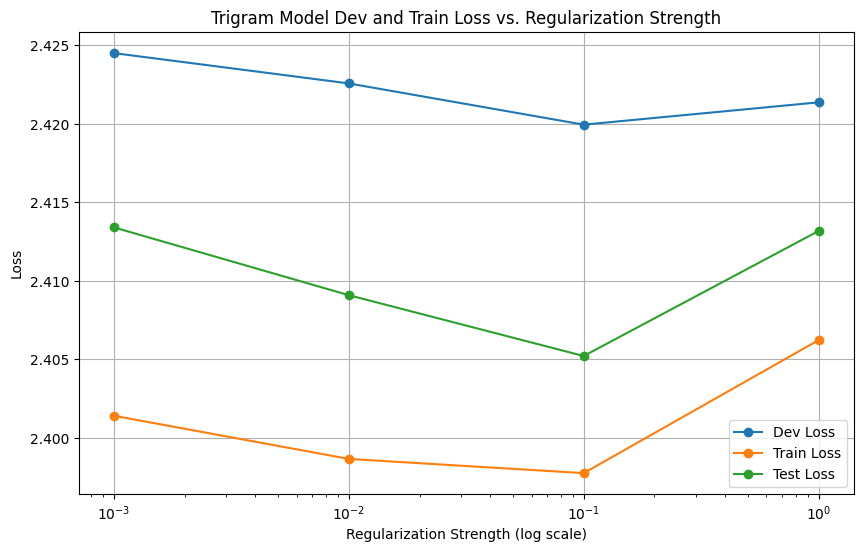

In [170]:
plot_losses(train_losses, dev_losses, test_losses) # for learning rate 10

In [171]:
# for learning rate 1

In [176]:
train_losses, dev_losses, test_losses = get_losses_for_regularization_values(x_train, y_train, x_dev, y_dev, x_test, y_test,1500,10)

Training with regularization: 1
Training with regularization: 0.1
Training with regularization: 0.01
Training with regularization: 0.001


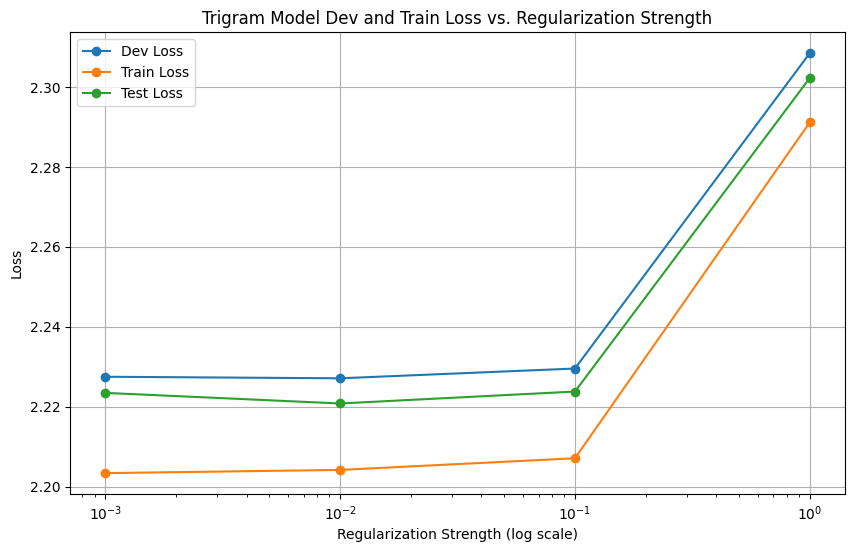

In [181]:
plot_losses(train_losses, dev_losses, test_losses)

## E04: bigram model has 1-hot. trigram model uses simple indexing instead of 1 hot encoding.

## E05: look up and use F.cross_entropy instead. You should achieve the same result. Can you think of why we'd prefer to use F.cross_entropy instead?

Answer: Its the same loss so we've been doing the same math behind the loss. Why Use F.cross_entropy Instead of Manual Code?

- Numerical stability:

  manual version does:
```
  counts = logits.exp()
  probs = counts / counts.sum(1, keepdims=True)
  loss = -probs[torch.arange(num), ys].log().mean()
```

  This is mathematically correct but numerically risky.
  exp(logits) can easily overflow for large logits.
  Then dividing and taking .log() can underflow.
  F.cross_entropy avoids this by using the log-sum-exp trick.

- Cleaner / less error-prone:
  You don’t have to reimplement softmax, normalization, indexing, etc.

In [174]:
def train_trigram_model_weights_cross_entropy(xs, ys, iterations, learning_rate, W = torch.randn((27, 27, 27), requires_grad=True, generator=g), reg = 0.01, print_loss=True):
  num = xs.nelement() // 2 # Number of trigram examples
  # Training loop with gradient descent
  for k in range(iterations):
    #Forward pass
    logits = W[xs[:, 0], xs[:, 1]]
    loss = F.cross_entropy(logits, ys) + reg*(W**2).mean() # Using F.cross_entropy
    if print_loss:
      print(loss.item())

    #Backward pass
    W.grad = None
    loss.backward()

    #Update weights
    W.data += -learning_rate * W.grad

  return W

In [175]:
W = torch.rand((27,27,27), requires_grad=True, generator=g)

In [182]:
W = train_trigram_model_weights_cross_entropy(x_train, y_train, 100, 10, W)

2.692889928817749
2.690121650695801
2.6873838901519775
2.6846776008605957
2.6820011138916016
2.679354190826416
2.6767361164093018
2.6741466522216797
2.671584367752075
2.669050455093384
2.6665427684783936
2.664062023162842
2.661607265472412
2.659177303314209
2.656773090362549
2.654393434524536
2.6520376205444336
2.6497058868408203
2.647397518157959
2.645111560821533
2.642848491668701
2.640608072280884
2.6383888721466064
2.6361918449401855
2.6340150833129883
2.63185977935791
2.6297245025634766
2.6276094913482666
2.625514030456543
2.6234378814697266
2.6213817596435547
2.6193432807922363
2.617324113845825
2.615323066711426
2.613340139389038
2.611374616622925
2.609426975250244
2.6074960231781006
2.6055819988250732
2.603684663772583
2.601804256439209
2.5999393463134766
2.598090410232544
2.5962576866149902
2.594439744949341
2.592637777328491
2.5908501148223877
2.5890777111053467
2.587319850921631
2.585576295852661
2.5838465690612793
2.5821313858032227
2.580430030822754
2.5787417888641357
2.57

In [183]:
test_loss = calculate_loss_for_trigram(W, x_test, y_test)
print(test_loss.item())

2.514418125152588


In [184]:
dev_loss = calculate_loss_for_trigram(W, x_dev, y_dev)
print(dev_loss.item())

2.520260810852051


In [185]:
train_loss = calculate_loss_for_trigram(W, x_train, y_train)
print(train_loss.item())

2.508082389831543


In [187]:
def calculate_cross_entropy_loss_for_trigram(W, xs, ys):
  num = xs.nelement() // 2
  logits = W[xs[:, 0], xs[:, 1]]
  loss = F.cross_entropy(logits, ys)

  return loss

In [188]:
ce_test_loss = calculate_cross_entropy_loss_for_trigram(W, x_test, y_test)
print(ce_test_loss.item())

2.514418363571167
